# 04 | Lock, predict, evaluate and report

SUPHANATTHAKON THOBSRI | 690631023 | 270702 Data Science Programming

**Scope:** nominal-source-clock-constrained retrospective benchmark. Original historical public release/revision is not certified; operational use remains blocked. Preserve real raw data and never manufacture outcomes.


## Locate the supplied project

Open this notebook inside the extracted project, or upload its complete project ZIP when using Colab. `ROOT` is the project folder; it is not a data-source timestamp. The archive guard rejects paths outside the extraction directory.


In [1]:
from pathlib import Path  # กำหนดตำแหน่งโครงการให้ใช้ได้ในเครื่องและ Colab
import sys  # ใช้โมดูลของโครงการกับ Python ที่กำลังรัน
import os  # อ่านกุญแจจากสภาพแวดล้อมโดยไม่บันทึกค่า
import json  # อ่านค่ากำหนดและข้อมูลอธิบายที่สร้างจริง
import zipfile  # ตรวจและแตกแพ็กเกจโครงการเมื่อจำเป็น
PROJECT_NAME = 'PM25_270702_690631023_Submission'  # ระบุชื่อโครงการฝุ่นและลำดับงานสี่ขั้น
BASE = Path.cwd().resolve()  # ใช้โฟลเดอร์ที่ notebook กำลังรัน
ROOT = BASE if (BASE / 'config.json').is_file() and (BASE / 'src' / 'workflow.py').is_file() else BASE / PROJECT_NAME  # เลือกโครงการที่แตกไฟล์ไว้ก่อน
if not (ROOT / 'src' / 'workflow.py').is_file():  # ค้นหาแพ็กเกจเมื่อเปิด notebook เดี่ยวใน Colab
    if not Path('/content').is_dir():  # การรันในเครื่องต้องมีโครงการที่แตก ZIP อยู่ข้าง notebook
        raise FileNotFoundError('Extract the supplied project ZIP and open its notebook first.')  # หยุดแทนการนำเข้าโค้ดคนละโครงการ
    from google.colab import files  # ขอแพ็กเกจโค้ดและข้อมูลที่มาพร้อม notebook
    uploaded = files.upload()  # อัปโหลด ZIP โครงการที่มีข้อมูลและโค้ดครบ
    archives = [name for name in uploaded if name.lower().endswith('.zip')]  # รับเฉพาะแพ็กเกจ ZIP
    assert len(archives) == 1, 'Upload exactly one project ZIP.'  # หยุดเมื่อเลือกแพ็กเกจได้ไม่แน่นอน
    with zipfile.ZipFile(BASE / archives[0]) as archive:  # เปิด ZIP ที่เลือกเพื่อตรวจความสมบูรณ์
        assert archive.testzip() is None, 'Project ZIP is damaged.'  # ตรวจความสมบูรณ์ ZIP ก่อนแตกไฟล์
        for member in archive.infolist():  # ตรวจปลายทางทุกไฟล์แทนการเชื่อชื่อใน ZIP
            destination = (BASE / member.filename).resolve()  # หาตำแหน่งปลายทางแบบสมบูรณ์ของทุกไฟล์
            assert destination.is_relative_to(BASE), 'Unsafe archive member.'  # ปฏิเสธตำแหน่งไฟล์ที่ออกนอกโฟลเดอร์ทำงาน
        archive.extractall(BASE)  # แตกไฟล์โครงการหลังตรวจความปลอดภัย
assert (ROOT / 'src' / 'workflow.py').is_file(), 'Expected PM2.5 project not found.'  # ตรวจว่ามีโมดูลของโครงการนี้จริง
sys.path.insert(0, str(ROOT / 'src'))  # ใช้โมดูลต้นฉบับที่แนบมากับโครงการ
print('PROJECT:', ROOT)  # แสดงโครงการที่จะรันos.environ['MPLBACKEND'] = 'Agg'  # สร้างไฟล์กราฟโดยไม่เปิดหน้าต่าง
for thread_variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:  # จำกัดเธรดก่อนนำเข้าไลบรารีคำนวณ
    os.environ.setdefault(thread_variable, '1')  # ใช้ค่าเริ่มต้นที่ทำซ้ำได้
os.chdir(ROOT)  # ให้ทุกพาธอ้างโครงการเดียวกัน
from common import load_config  # อ่าน contract รุ่นนี้
ROOT, CONFIG = load_config()  # ตรวจเวลาออกคำทำนายและรุ่นโครงการ
from IPython.display import display, Image, HTML  # แสดงหลักฐานและรูปภาพที่สร้างจริง
import pandas as pd  # อ่านตารางโดยรักษาบทบาทของข้อมูล
import numpy as np  # ตรวจค่าตัวเลขและลำดับเวลา
import workflow as lab  # ใช้ orchestration เดียวกับสคริปต์
from environment_check import check_environment  # ตรวจ dependency ที่ล็อกรุ่น
dependency_evidence = check_environment(ROOT, strict=True)  # ไม่เปลี่ยนรุ่นเงียบ ๆ
display(HTML("<style>.jp-CodeCell .jp-InputArea-editor,.input_area{background:#f2f2f2!important;border:1px solid #ccc}</style>"))  # รักษาพื้นเซลล์โค้ดสีเทา


PROJECT: C:\Users\User\Documents\Codex\2026-10-12\computer-assignment-2-2-string-grammar\outputs\PM25_270702_690631023_Submission


## Reload the fixed experiment and verify it

This notebook compares all 12 source/window settings. Primary learner Ridge minimizes squared error plus α·Σβ², with a fold-fitted StandardScaler and unpenalized intercept. α∈{0.1,1,10,100,1000}; training-only temporal CV chooses it. Secondary HGB uses200 iterations, learning rate 0.05, minimum leaf 20, leaf nodes 7/15 and L2=0/10. Predictions are clipped at 0 in CV and final scoring, consistently. HGB does not replace the primary learner after seeing test scores.


In [2]:
daily = lab.load_prepared(ROOT, CONFIG)  # อ่านตารางที่ตรวจ hash แล้ว
from prepare_data import build_experiments  # รักษาคำถาม 12 แบบเดิม
X, specifications, eligible = build_experiments(ROOT, CONFIG, daily)  # ใช้ full-calendar lags และ common cohort
from check_dataset import check_dataset, require_pass  # ใช้ checker ชุดเดียวกับ CLI
require_pass(check_dataset(ROOT, CONFIG, daily, X, specifications, eligible))  # ไม่ฝึกต่อหาก target หรือ offset ผิด


{'owner': 'PROJECT-OWNED DATASET CHECKER',
 'stage': 'dataset',
 'temporal_cutoff_status': 'PASS',
 'temporal_cutoff_scope': 'Calendar, target, source offsets and outer label maturity; CV/scaling are checked in the model stage.',
 'checked_at_utc': '2026-10-23T18:53:59.972570+00:00',
 'run_id': '3b68d357b38043b79d4ea208707aa660',
 'technical_status': 'PASS',
 'historical_publication_status': 'UNVERIFIED',
 'operational_readiness': 'NOT_PASSED',
 'checks': [{'check': 'full_calendar_including_buffers',
   'status': 'PASS',
   'evidence': '739 calendar rows; no compressed-day lagging.'},
  {'check': 'tomorrow_after_issue_target',
   'status': 'PASS',
   'evidence': 'History anchor =D-1; issue=D07; target=D+1, hence anchor+2.'},
  {'check': 'issue_and_target_clock',
   'status': 'PASS',
   'evidence': '07 Thai issue; target starts17h and ends41h later.'},
  {'check': 'target_41hour_finish',
   'status': 'PASS',
   'evidence': 'Label completion distinct from public availability.'},
  {'chec

## Verify split and answer separation

`B0_persistence=P(D−1)` and `B1_provider_forecast` use the same test days. B1 is an earlier CAMS forecast for the target interval, not the target vintage and never a learned feature. `C0_training_majority` is a warning-only baseline, so its arbitrary numeric encoding is not assigned MAE/RMSE. Software isolation does not restore a new unseen holdout after prior exploration.


In [3]:
from evaluate_forecast import lock_experiment, verify_receipts  # จัดการการล็อกและ receipt ของรอบจริง
display(pd.read_csv(ROOT / 'outputs/results/chronology.csv'))  # แสดงรอยต่อที่ผ่าน label maturity
test_feature_columns = pd.read_csv(ROOT / 'data/processed/evaluation_inputs/test_features.csv', nrows=0).columns.tolist()  # อ่านเฉพาะหัวคอลัมน์ input ของ test
assert not {'y_true', 'pm25_tomorrow', 'exceed_tomorrow'} & set(test_feature_columns)  # ไม่ให้คำตอบเป็นคอลัมน์ทำนาย
print('Answer-free test columns:', len(test_feature_columns))  # นับ input โดยไม่เปิดคำตอบ


,partition,n,first_target,last_target,first_issue_utc,last_label_complete_utc,positive_days
0,train,231,2024-01-28 00:00:00,2024-09-29 00:00:00,2024-01-27 00:00:00+00:00,2024-09-29 17:00:00+00:00,7
1,validation,91,2024-10-01 00:00:00,2024-12-30 00:00:00,2024-09-30 00:00:00+00:00,2024-12-30 17:00:00+00:00,3
2,test,365,2025-01-01 00:00:00,2025-12-31 00:00:00,2024-12-31 00:00:00+00:00,2025-12-31 17:00:00+00:00,30


Answer-free test columns: 89


## Tune on training, choose on validation, then freeze

Each setting is tuned only inside training CV. Validation MAE chooses the primary Ridge group/window with deterministic tie breaks. Final estimators refit on mature train+validation labels before the first test issue. Every source, configuration, input and model hash is locked. Answer hashes bind provenance; test answers are not used by fitting or selection. Editing any src file, including checker/report code, requires a new lock and actual receipts.


In [4]:
forecast_plan = lock_experiment(ROOT, CONFIG)  # ฝึกจาก train/CV เลือกจาก validation และล็อก source ปัจจุบัน
display(pd.DataFrame(json.loads((ROOT / 'outputs/results/tuning.json').read_text(encoding='utf-8'))))  # รายงานพารามิเตอร์ทุกแบบ
print('VALIDATION-SELECTED:', forecast_plan['selection'])  # ไม่เลือกผู้ชนะใหม่จาก test


ridge__H1_3d: training-only tuning and validation finished; refit saved without test labels


ridge__H1_5d: training-only tuning and validation finished; refit saved without test labels


ridge__H1_7d: training-only tuning and validation finished; refit saved without test labels


ridge__H2_3d: training-only tuning and validation finished; refit saved without test labels


ridge__H2_5d: training-only tuning and validation finished; refit saved without test labels


...

hgb__H4_3d: training-only tuning and validation finished; refit saved without test labels


hgb__H4_5d: training-only tuning and validation finished; refit saved without test labels


hgb__H4_7d: training-only tuning and validation finished; refit saved without test labels


,family,experiment,parameters,inner_cv_MAE,train_rows,refit_rows,feature_count,validation_MAE
0,ridge,H1_3d,{'model__alpha': 10.0},5.250706,231,322,9,5.166434
1,ridge,H1_5d,{'model__alpha': 1.0},5.513380,231,322,15,5.921916
2,ridge,H1_7d,{'model__alpha': 1.0},5.311879,231,322,21,5.691023
3,ridge,H2_3d,{'model__alpha': 100.0},5.491617,231,322,30,7.332754
4,ridge,H2_5d,{'model__alpha': 100.0},5.882904,231,322,50,7.958584
5,ridge,H2_7d,{'model__alpha': 1000.0},6.191470,231,322,70,7.478884
6,ridge,H3_3d,{'model__alpha': 10.0},4.130965,231,322,15,7.612877
7,ridge,H3_5d,{'model__alpha': 100.0},4.102960,231,322,25,8.938779
8,ridge,H3_7d,{'model__alpha': 10.0},4.119710,231,322,35,8.313565
9,ridge,H4_3d,{'model__alpha': 100.0},5.408992,231,322,36,8.022757


VALIDATION-SELECTED: {'primary_family': 'ridge', 'experiment': 'H1_3d', 'selection_partition': 'validation only', 'selection_metric': 'MAE', 'validation_MAE': np.float64(5.1664338694962675), 'test_was_not_used_for_selection': True, 'data_status': 'Previously explored historical test; prediction-stage isolation does not restore an unseen holdout.'}


## Commit predictions without opening test answers

The prediction function reads frozen models and answer-free test features. It writes predictions and their hash receipt before evaluation; the SQL commitment reads no answer table. This is an inspectable interface boundary on historical data, not protection against a malicious analyst or proof of real-time availability.


In [5]:
from stages import commit_predictions  # ใช้ขั้นทำนายและ SQL commitment ร่วมกับสคริปต์
prediction_receipt, sql_commitment = commit_predictions(ROOT)  # ไม่ส่ง target ของช่วง test เข้า predict
print(json.dumps(prediction_receipt, indent=2))  # เก็บรหัสรอบ เวลา และ hash ของคำทำนาย
print('SQL COMMITMENT:', sql_commitment)  # ตรวจว่าบันทึกคำทำนายก่อนเปิดคำตอบ


{
  "run_id": "21ffe8b85b43434fac5c2af488097618",
  "locked_plan_sha256": "87847cbc90bd67552146b3a3b56bf7eaa44a7d773798434004fd03aec28e665a",
  "predicted_at_utc": "2026-10-23T18:54:22.142432+00:00",
  "prediction_sha256": "d8c16b15fcb48486985e6637e061bb48e1eb7b2f4f07f550c27c9a5bc4649131",
  "rows": 365,
  "input_columns": [
    "date",
    "target_date",
    "forecast_origin_utc",
    "pm25_mean_lag0",
    "pm25_mean_lag1",
    "pm25_mean_lag2",
    "pm25_mean_lag3",
    "pm25_mean_lag4",
    "pm25_mean_lag5",
    "pm25_mean_lag6",
    "pm25_min_lag0",
    "pm25_min_lag1",
    "pm25_min_lag2",
    "pm25_min_lag3",
    "pm25_min_lag4",
    "pm25_min_lag5",
    "pm25_min_lag6",
    "pm25_max_lag0",
    "pm25_max_lag1",
    "pm25_max_lag2",
    "pm25_max_lag3",
    "pm25_max_lag4",
    "pm25_max_lag5",
    "pm25_max_lag6",
    "temperature_mean_lag0",
    "temperature_mean_lag1",
    "temperature_mean_lag2",
    "temperature_mean_lag3",
    "temperature_mean_lag4",
    "temperature_mean_

## Inspect committed prediction coverage

There must be one prediction per retained test date for every baseline and setting. No missing prediction is silently dropped to improve a score. Dates are join keys, not predictors.


In [6]:
committed = pd.read_csv(ROOT / 'outputs/results/predictions_test_blind.csv')  # อ่านคำทำนายที่ commit แล้วเท่านั้น
assert 'y_true' not in committed and not committed.isna().any().any()  # ตรวจว่าไม่มีคำตอบหรือคำทำนายขาด
display(committed.head())  # ตัวอย่างผลที่ยังไม่รวมคำตอบ
print('Committed test dates:', len(committed))  # ทุกแบบต้องมีจำนวนวันเท่ากัน


,date,target_date,B0_persistence,B1_provider_forecast,C0_training_majority,ridge__H1_3d,ridge__H1_5d,ridge__H1_7d,ridge__H2_3d,ridge__H2_5d,...,hgb__H1_7d,hgb__H2_3d,hgb__H2_5d,hgb__H2_7d,hgb__H3_3d,hgb__H3_5d,hgb__H3_7d,hgb__H4_3d,hgb__H4_5d,hgb__H4_7d
0,2024-12-30,2025-01-01,32.933368,36.110911,0.0,31.854725,34.146913,34.483421,30.438364,31.299888,...,26.614641,27.953487,27.304089,28.118430,27.452891,26.644177,25.178638,27.161556,28.746049,28.774054
1,2024-12-31,2025-01-02,33.286869,39.838849,0.0,31.052957,30.941680,34.085741,29.942869,30.396226,...,28.181169,29.293414,30.743566,30.389889,28.008592,28.438829,29.373387,29.499791,32.292262,31.269969
2,2025-01-01,2025-01-03,35.228374,36.490239,0.0,31.299935,30.191015,32.940730,30.327789,30.544594,...,28.010861,30.359482,31.280816,32.545008,31.999905,29.759568,30.884199,32.632645,33.027369,32.557576
3,2025-01-02,2025-01-04,37.767389,33.558732,0.0,33.531149,34.193391,34.353938,31.376755,31.898125,...,29.118027,28.340495,27.502727,29.757701,32.856793,29.917791,28.285908,28.932999,30.337785,30.207678
4,2025-01-03,2025-01-05,34.406919,41.130827,0.0,32.249359,32.059583,35.746495,30.296303,30.530344,...,29.926862,28.014461,30.595052,31.617554,31.210917,32.074054,30.273381,27.893105,31.381136,30.305091


Committed test dates: 365


## Open historical answers and evaluate

The scoring stage verifies lock, receipt and identical keys before opening answers. MAE is primary; RMSE describes large errors. At the fixed lab threshold 37.5µg/m³, precision, recall, F1, FP and FN describe modeled exceedance warnings. They are not station-validated health-warning performance. All12 settings are reported, including negative or inconclusive findings.


In [7]:
from stages import score_and_diagnose  # ใช้ขั้นประเมินแยกจากขั้น predict
scores, comparisons, diagnostic_evidence = score_and_diagnose(ROOT, CONFIG)  # เปิดคำตอบหลังตรวจ receipt และคำนวณทุกแบบ
display(scores.query('partition == "test" and family == "baseline"'))  # รายงาน baseline ก่อนโมเดล
print('RECEIPTS:', verify_receipts(ROOT)['status'])  # ยืนยันลำดับ lock -> predict -> score ของรอบปัจจุบัน


,partition,family,experiment,hypothesis,window,n,MAE,RMSE,TP,TN,FP,FN,positive_days,threshold,precision,recall,F1
27,test,baseline,B0_persistence,baseline,1,365,6.281885,8.766233,11,316,19,19,30,37.5,0.366667,0.366667,0.366667
28,test,baseline,B1_provider_forecast,provider_reference,0,365,3.739489,5.195112,20,310,25,10,30,37.5,0.444444,0.666667,0.533333
29,test,baseline,C0_training_majority,warning_only,0,365,NaN,NaN,0,335,0,30,30,37.5,NaN,0.000000,0.000000


RECEIPTS: PASS


## Compare twelve settings on identical dates

The heatmap is descriptive. The validation-selected candidate remains fixed even when another setting has the lowest test MAE. Report the provider reference alongside persistence because the target itself is a CAMS product.


window,3,5,7
hypothesis,,,
H1,6.136589,6.235624,6.585287
H2,5.701382,5.705052,5.791629
H3,6.105306,5.795755,6.283804
H4,5.741119,5.754218,5.755463


,partition,family,experiment,hypothesis,window,n,MAE,RMSE,TP,TN,FP,FN,positive_days,threshold,precision,recall,F1
30,test,ridge,H1_3d,H1,3,365,6.136589,8.512220,7,327,8,23,30,37.5,0.466667,0.233333,0.311111
31,test,ridge,H1_5d,H1,5,365,6.235624,8.619415,6,324,11,24,30,37.5,0.352941,0.200000,0.255319
32,test,ridge,H1_7d,H1,7,365,6.585287,8.982586,8,322,13,22,30,37.5,0.380952,0.266667,0.313725
33,test,ridge,H2_3d,H2,3,365,5.701382,8.111815,6,331,4,24,30,37.5,0.600000,0.200000,0.300000
34,test,ridge,H2_5d,H2,5,365,5.705052,8.010418,6,332,3,24,30,37.5,0.666667,0.200000,0.307692
35,test,ridge,H2_7d,H2,7,365,5.791629,8.251623,4,332,3,26,30,37.5,0.571429,0.133333,0.216216
36,test,ridge,H3_3d,H3,3,365,6.105306,8.390845,12,324,11,18,30,37.5,0.521739,0.400000,0.452830
37,test,ridge,H3_5d,H3,5,365,5.795755,7.929159,9,324,11,21,30,37.5,0.450000,0.300000,0.360000
38,test,ridge,H3_7d,H3,7,365,6.283804,8.550014,14,320,15,16,30,37.5,0.482759,0.466667,0.474576
39,test,ridge,H4_3d,H4,3,365,5.741119,8.022575,7,330,5,23,30,37.5,0.583333,0.233333,0.333333


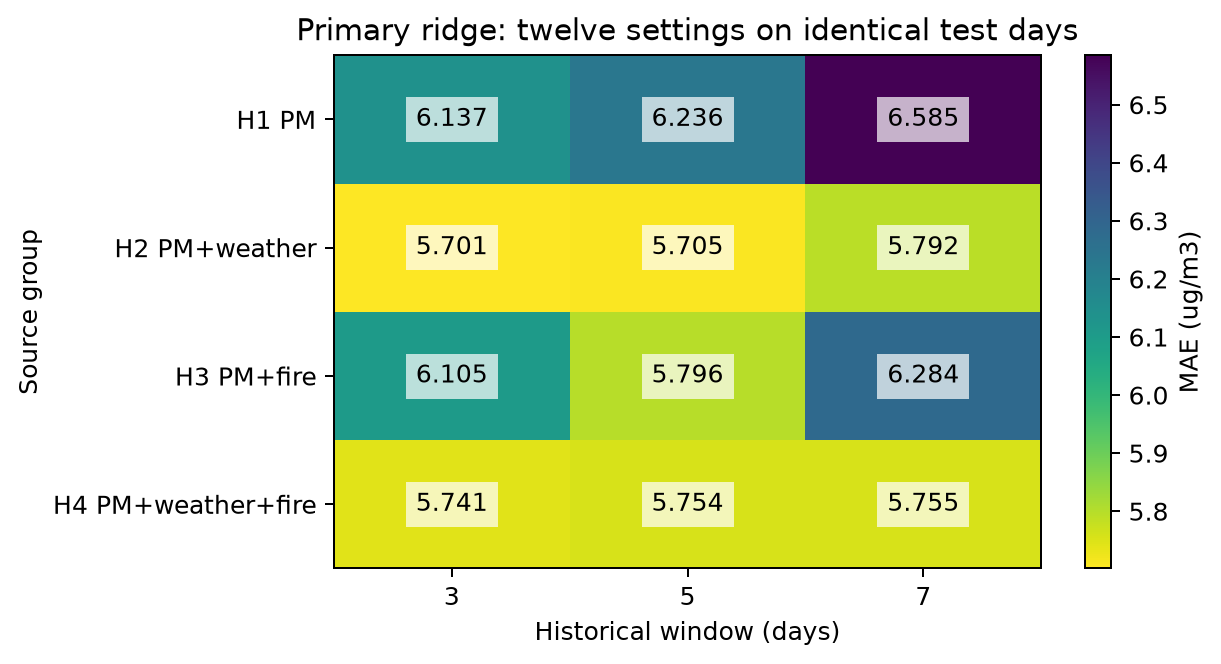

In [8]:
import analyse as analysis  # ใช้กราฟจาก metrics ที่บันทึกจริง
mae_matrix = analysis.model_figures(ROOT, CONFIG, scores)  # สร้าง heatmap และกราฟ FP/FN
display(mae_matrix)  # เทียบทุกกลุ่มและหน้าต่าง
display(scores.query('partition == "test" and family == "ridge"'))  # ไม่ซ่อนแบบที่ทำนายแย่กว่า baseline
display(Image(filename=str(ROOT / 'outputs/figures/04_twelve_settings.png'), width=850))  # ดูผลเปรียบเทียบครบ 12 แบบ


## Answer incremental questions and uncertainty

H1−B0 tests PM history against persistence. H2−H1 tests weather; H3−H1 tests fire; H4−H2 tests fire conditional on weather; H4−H3 tests weather conditional on fire. Negative paired absolute-error differences favor the added group. Moving-block95% intervals use14-day blocks,1000 repeats, seed42, with calendar gaps/year boundaries respected. They are pointwise exploratory intervals, not multiplicity-adjusted hypothesis confirmations. Windows are selected on validation within each group.


In [9]:
display(comparisons.query('family == "ridge"')[['window', 'comparison', 'estimate', 'ci_low', 'ci_high', 'interpretation']])  # แสดงทั้งทิศทางและความไม่แน่นอน
display(pd.read_csv(ROOT / 'outputs/results/twelve_answers.csv').query('family == "ridge"'))  # ตอบครบ 12 คำถามย่อยตามหลักฐาน
display(pd.read_csv(ROOT / 'outputs/results/window_selection_by_group.csv').query('family == "ridge"'))  # หน้าต่างที่เลือกจาก validation ไม่ใช่ test


,window,comparison,estimate,ci_low,ci_high,interpretation
0,3,H1-B0,-0.145297,-0.527682,0.237710,inconclusive
1,3,H2-H1,-0.435207,-0.761382,-0.158518,interval_below_zero
2,3,H3-H1,-0.031282,-0.252319,0.155278,inconclusive
3,3,H4-H2,0.039737,-0.069676,0.148039,inconclusive
4,3,H4-H3,-0.364188,-0.816732,0.068120,inconclusive
5,5,H1-B0,-0.046262,-0.429954,0.357276,inconclusive
6,5,H2-H1,-0.530571,-0.913026,-0.214100,interval_below_zero
7,5,H3-H1,-0.439868,-0.692955,-0.235880,interval_below_zero
8,5,H4-H2,0.049166,-0.078283,0.172021,inconclusive
9,5,H4-H3,-0.041538,-0.375999,0.263983,inconclusive


,family,experiment,subhypothesis,MAE,recall,FP,FN,answer,scope
0,ridge,H1_3d,H1a,6.136589,0.233333,8,23,H1-B0: no clear MAE difference; interval spans...,Retrospective CAMS outcome; source-publication...
1,ridge,H1_5d,H1b,6.235624,0.200000,11,24,H1-B0: no clear MAE difference; interval spans...,Retrospective CAMS outcome; source-publication...
2,ridge,H1_7d,H1c,6.585287,0.266667,13,22,H1-B0: no clear MAE difference; interval spans...,Retrospective CAMS outcome; source-publication...
3,ridge,H2_3d,H2a,5.701382,0.200000,4,24,H2-H1: lower MAE with pointwise exploratory in...,Retrospective CAMS outcome; source-publication...
4,ridge,H2_5d,H2b,5.705052,0.200000,3,24,H2-H1: lower MAE with pointwise exploratory in...,Retrospective CAMS outcome; source-publication...
5,ridge,H2_7d,H2c,5.791629,0.133333,3,26,H2-H1: lower MAE with pointwise exploratory in...,Retrospective CAMS outcome; source-publication...
6,ridge,H3_3d,H3a,6.105306,0.400000,11,18,H3-H1: no clear MAE difference; interval spans...,Retrospective CAMS outcome; source-publication...
7,ridge,H3_5d,H3b,5.795755,0.300000,11,21,H3-H1: lower MAE with pointwise exploratory in...,Retrospective CAMS outcome; source-publication...
8,ridge,H3_7d,H3c,6.283804,0.466667,15,16,H3-H1: lower MAE with pointwise exploratory in...,Retrospective CAMS outcome; source-publication...
9,ridge,H4_3d,H4a,5.741119,0.233333,5,23,H4-H2: no clear MAE difference; interval spans...,Retrospective CAMS outcome; source-publication...


,family,hypothesis,selected_window,validation_MAE,selection_partition
0,ridge,H1,3,5.166434,validation only
1,ridge,H2,3,7.332754,validation only
2,ridge,H3,3,7.612877,validation only
3,ridge,H4,3,8.022757,validation only


## Inspect warning failures and learner robustness

Lower MAE does not automatically mean fewer missed exceedances. Every missed day remains visible. HGB and 7/14/28-day block sensitivity are declared secondary diagnostics; do not use them to change the primary learner, interval length, threshold or source mask after viewing test.


,date,target_date,y_true,B0_persistence,ridge__H1_3d,model_error,actual_above_threshold,model_outcome,baseline_outcome
0,2024-12-31,2025-01-02,37.767389,33.286869,31.052957,-6.714432,0.267389,FN,FN
1,2025-01-04,2025-01-06,38.059540,32.488616,34.021797,-4.037743,0.559540,FN,FN
2,2025-01-26,2025-01-28,43.726273,28.446427,26.671172,-17.055101,6.226273,FN,FN
3,2025-01-27,2025-01-29,37.515658,33.483388,29.011395,-8.504263,0.015658,FN,FN
4,2025-02-06,2025-02-08,38.837717,34.120322,30.961760,-7.875957,1.337717,FN,FN
5,2025-02-16,2025-02-18,37.535952,32.101908,28.401092,-9.134860,0.035952,FN,FN
6,2025-02-17,2025-02-19,47.408976,31.772142,29.772259,-17.636717,9.908976,FN,FN
7,2025-02-18,2025-02-20,45.609738,37.535952,32.648498,-12.961239,8.109738,FN,TP
8,2025-02-19,2025-02-21,37.642475,47.408976,36.531499,-1.110976,0.142475,FN,TP
9,2025-03-03,2025-03-05,42.853088,28.078371,25.637122,-17.215966,5.353088,FN,FN


,experiment,MAE_ridge,MAE_hgb,delta_hgb_minus_ridge
0,H1_3d,6.136589,6.496545,0.359956
1,H1_5d,6.235624,6.704336,0.468712
2,H1_7d,6.585287,6.799056,0.213769
3,H2_3d,5.701382,6.343998,0.642616
4,H2_5d,5.705052,6.713063,1.008010
5,H2_7d,5.791629,6.644087,0.852458
6,H3_3d,6.105306,6.360263,0.254957
7,H3_5d,5.795755,6.362379,0.566623
8,H3_7d,6.283804,6.653477,0.369673
9,H4_3d,5.741119,6.220922,0.479803


,family,window,comparison,interpretation,is_primary_block,scope,estimate,ci_low,ci_high,n,block_days,bootstrap_repeats,segment_lengths
0,ridge,3,H1-B0,inconclusive,False,"Secondary sensitivity, not a basis for changin...",-0.145297,-0.528868,0.223279,365,7,1000,[365]
1,ridge,3,H1-B0,inconclusive,True,"Secondary sensitivity, not a basis for changin...",-0.145297,-0.527682,0.237710,365,14,1000,[365]
2,ridge,3,H1-B0,inconclusive,False,"Secondary sensitivity, not a basis for changin...",-0.145297,-0.459691,0.236437,365,28,1000,[365]
3,ridge,3,H2-H1,interval_below_zero,False,"Secondary sensitivity, not a basis for changin...",-0.435207,-0.738845,-0.168519,365,7,1000,[365]
4,ridge,3,H2-H1,interval_below_zero,True,"Secondary sensitivity, not a basis for changin...",-0.435207,-0.761382,-0.158518,365,14,1000,[365]
5,ridge,3,H2-H1,interval_below_zero,False,"Secondary sensitivity, not a basis for changin...",-0.435207,-0.791802,-0.183783,365,28,1000,[365]
6,ridge,3,H3-H1,inconclusive,False,"Secondary sensitivity, not a basis for changin...",-0.031282,-0.232189,0.162386,365,7,1000,[365]
7,ridge,3,H3-H1,inconclusive,True,"Secondary sensitivity, not a basis for changin...",-0.031282,-0.252319,0.155278,365,14,1000,[365]
8,ridge,3,H3-H1,inconclusive,False,"Secondary sensitivity, not a basis for changin...",-0.031282,-0.250449,0.173166,365,28,1000,[365]
9,ridge,3,H4-H2,inconclusive,False,"Secondary sensitivity, not a basis for changin...",0.039737,-0.069632,0.148677,365,7,1000,[365]


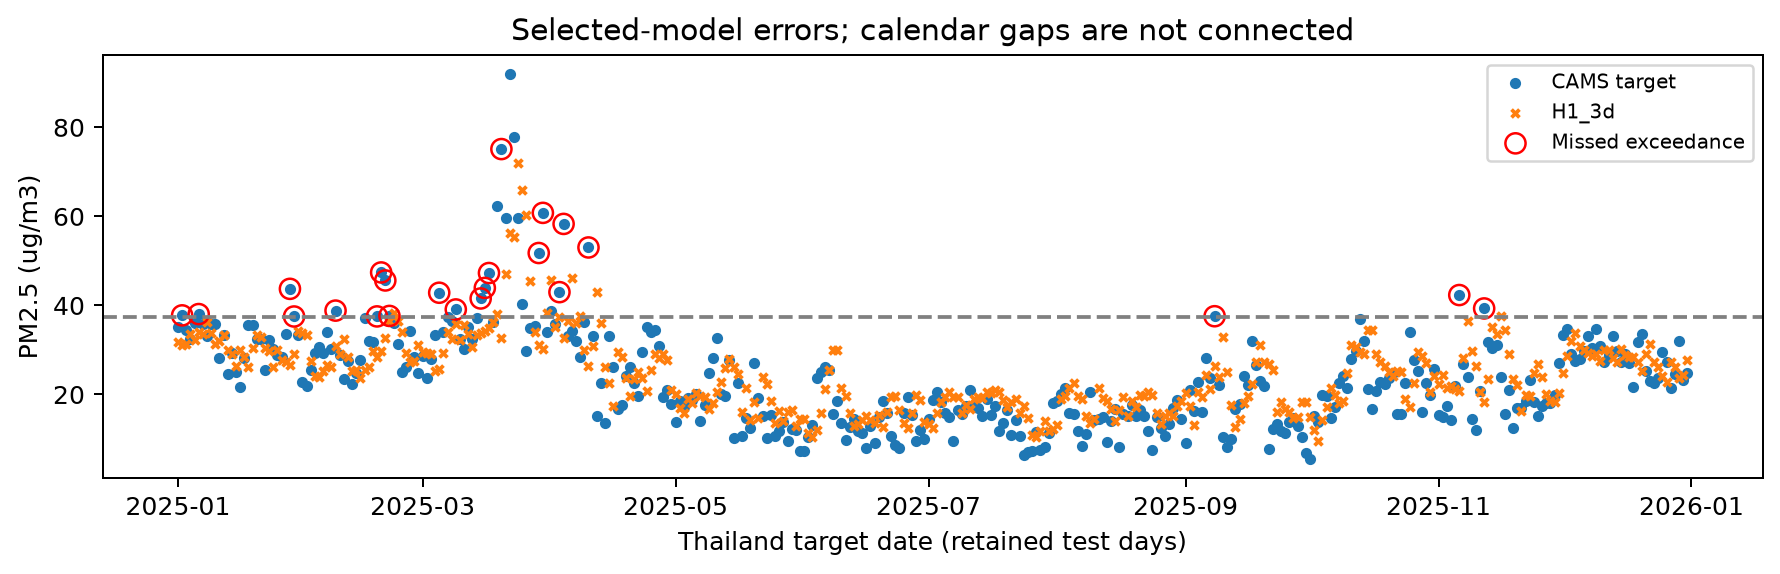

In [10]:
display(pd.read_csv(ROOT / 'outputs/results/missed_day_details.csv'))  # แสดงทุกวันที่โมเดลพลาดเกินเกณฑ์
display(pd.read_csv(ROOT / 'outputs/results/learner_robustness.csv'))  # เปรียบเทียบ learner รองโดยไม่เลือกใหม่
display(pd.read_csv(ROOT / 'outputs/results/bootstrap_sensitivity.csv').query('family == "ridge"'))  # ตรวจความไวต่อความยาว block ที่กำหนดไว้
display(Image(filename=str(ROOT / 'outputs/figures/07_warning_days.png'), width=900))  # แสดงคำตอบและความผิดพลาดตามวันจริง


## Keep station evidence and deployment claims in scope

C6 is the preserved contemporary station/Open-Meteo rolling24h comparison with boundary uncertainty. It does not validate the new historical ADS profiles. C4 retains one receptor; no second independent location is invented. Nominal source-clock improvements do not certify original publication or operational safety.

Subject to station QA, Air4Thai is the local empirical reference. The contemporary modeled snapshot does not validate the historical ADS targets.


In [11]:
display(pd.read_csv(ROOT / 'outputs/results/station_crosscheck.csv'))  # รายงาน measured reference แยกจาก target ของโมเดล
print(json.dumps(json.loads((ROOT / 'outputs/results/spatial_resolution_audit.json').read_text(encoding='utf-8')), indent=2))  # ไม่สร้างจุดศึกษาที่สองจากกริดเดียวกัน
print(json.dumps(json.loads((ROOT / 'outputs/results/availability_gate.json').read_text(encoding='utf-8')), indent=2))  # คงข้อจำกัด original release และ operational gate ตามจริง


,station_id,primary,station_name,station_latitude,station_longitude,reported_at_local,timezone,unit,reference_pm25_rolling24h,cams_pm25_mean24_samples,signed_difference_cams_minus_station,absolute_difference,cams_one_hour_earlier_window_mean,difference_with_earlier_boundary,matched_hour_count,cams_grid_latitude,cams_grid_longitude,model_window_first_sample,model_window_last_sample
0,36t,True,Yupparaj Wittayalai School,18.790933,98.99000,2026-10-16T21:00:00,Asia/Bangkok,ug/m3,13.3,12.966667,-0.333333,0.333333,13.095833,-0.204167,24,18.800003,99.0,2026-10-15T22:00:00,2026-10-16T21:00:00
1,35t,False,"City Hall, Chiangmai",18.840732,98.96978,2026-10-16T21:00:00,Asia/Bangkok,ug/m3,16.4,12.966667,-3.433333,3.433333,13.095833,-3.304167,24,18.800003,99.0,2026-10-15T22:00:00,2026-10-16T21:00:00


{
  "status": "ONE_RECEPTOR_RETAINED",
  "requested_receptor": {
    "latitude": 18.7883,
    "longitude": 98.9853
  },
  "PM_native_ADS_point": {
    "latitude": 18.8,
    "longitude": 98.8,
    "grid_degrees": 0.4
  },
  "weather_response_grid": {
    "latitude": 18.802475,
    "longitude": 99.02344
  },
  "station_coordinate_comparison": {
    "status": "COMPLETED",
    "requested_stations": [
      "36t",
      "35t"
    ],
    "returned_grid_36t": [
      18.800003,
      99.0
    ],
    "returned_grid_35t": [
      18.800003,
      99.0
    ],
    "hourly_time_axes_equal": true,
    "hourly_values_identical": true,
    "hours_compared": 72,
    "maximum_absolute_grid_difference": 0.0,
    "measured_station_values": [
      13.3,
      16.4
    ],
    "C4_conclusion": "The main study has one receptor. Both station-coordinate requests return identical CAMS series; no spatial contrast is justified."
  },
  "fire_region": {
    "west": 97.0,
    "south": 17.5,
    "east": 101.0,
    

## Verify evidence and generate the report

Scientific invariants, recomputed metrics, SQL↔CSV values, source locks and the operational rejection are rechecked. The English report keeps the existing format and grey Thai-comment code listing. It separates original-model strengths, targeted structural fixes and numerical outcomes. Cross-version raw MAE is not an algorithm-only improvement estimate because target vintage, horizon, period and cohort differ.


In [12]:
from stages import report_ready_artifacts  # ใช้รายงานและการตรวจร่วมกับสคริปต์
report_evidence = report_ready_artifacts(ROOT, CONFIG, daily, X, specifications, eligible)  # ตรวจ science, SQL และสร้าง workflow
from report import build_report  # สร้างรายงานจากผลรอบเดียวกัน
documents = build_report(ROOT, CONFIG)  # คงรูปแบบเดิมและเปลี่ยนเฉพาะเนื้อหาที่หลักฐานใหม่เกี่ยวข้อง
print('TECHNICAL VERIFICATION:', report_evidence['science']['status'])  # ไม่แปลง technical PASS เป็นการรับรอง publication
print('DOCUMENTS:', documents)  # ตรวจจำนวนหน้าและตำแหน่งจริง


TECHNICAL VERIFICATION: PASS
DOCUMENTS: {'report': 'C:\\Users\\User\\Documents\\Codex\\2026-10-12\\computer-assignment-2-2-string-grammar\\outputs\\PM25_270702_690631023_Submission\\report\\report.pdf', 'physical_pages': 35, 'main_pages': 12, 'appendix_pages': 23, 'proposal_pages': 1, 'listed_code_cells': 30}


## Build a candidate package

The local runner saves all notebooks and rebuilds the report after every final cell before sealing with `require_executed=True`. This in-notebook candidate can still show pending saved cells. Actual execution evidence and external student attestations are separate; no signature, repository publication or video is fabricated.


In [13]:
candidate_zip, execution_evidence = lab.make_submission(ROOT)  # ตรวจไฟล์และสร้าง candidate จากสิ่งที่บันทึกจริง
print('CANDIDATE ZIP:', candidate_zip)  # ตัวรันจะ seal ใหม่หลังบันทึกครบทุกเซลล์
print('SAVED EXECUTION EVIDENCE:', execution_evidence)  # ไม่ประดิษฐ์ execution_count ให้เซลล์ที่ยังไม่บันทึก


CANDIDATE ZIP: C:\Users\User\Documents\Codex\2026-10-12\computer-assignment-2-2-string-grammar\outputs\PM25_270702_690631023_Submission.zip
SAVED EXECUTION EVIDENCE: {'notebooks': [{'notebook': '01_fetch_data.ipynb', 'code_cells': 6, 'executed_code_cells': 6, 'stored_errors': 0, 'every_code_line_commented': True, 'fully_executed': True}, {'notebook': '02_prepare_data.ipynb', 'code_cells': 6, 'executed_code_cells': 6, 'stored_errors': 0, 'every_code_line_commented': True, 'fully_executed': True}, {'notebook': '03_analyse.ipynb', 'code_cells': 4, 'executed_code_cells': 4, 'stored_errors': 0, 'every_code_line_commented': True, 'fully_executed': True}, {'notebook': '04_model.ipynb', 'code_cells': 14, 'executed_code_cells': 12, 'stored_errors': 0, 'every_code_line_commented': True, 'fully_executed': False}], 'notebook_count': 4, 'code_cells': 30, 'executed_code_cells': 28, 'stored_errors': 0, 'every_code_line_commented': True, 'fully_executed': False}


## Optional Colab sealing after exporting all four notebooks

Keep False for local `run_all.py`, which records all kernels automatically. In Colab, export all four actually executed notebooks, then enable this cell to verify their unchanged source and real saved outputs before sealing. No source, date or metric is accepted merely because an uploaded notebook claims success.


In [14]:
SEAL_COLAB_EXPORTS = False  # เปิดใช้หลังรันครบและส่งออก notebook จริงทั้งสี่ไฟล์
if SEAL_COLAB_EXPORTS:  # ไม่ให้การรันปกติหยุดรอการโต้ตอบ
    import nbformat  # ตรวจต้นฉบับ จำนวนรัน และ error ของ notebook จริง
    import re  # ยอมให้เปลี่ยนเฉพาะโหมดดึงข้อมูลและค่าจัดแพ็กเกจที่กำหนด
    import tempfile  # แยกไฟล์อัปโหลดจากต้นฉบับจนกว่าจะตรวจผ่าน
    from google.colab import files  # อัปโหลด notebook ที่ส่งออกจากการรันจริงทั้งสี่ไฟล์
    expected_books = {name: nbformat.read(ROOT / name, as_version=4) for name in lab.NOTEBOOKS}  # เก็บต้นฉบับที่คาดหวังก่อนอัปโหลดไฟล์
    previous_directory = Path.cwd()  # กลับเข้าโฟลเดอร์โครงการหลังอัปโหลด
    with tempfile.TemporaryDirectory() as upload_folder:  # แยกไฟล์อัปโหลดจากพื้นที่ตรวจต้นฉบับ
        try:  # คืนโฟลเดอร์ทำงานแม้การอัปโหลดผิดพลาด
            os.chdir(upload_folder)  # ป้องกันไฟล์อัปโหลดเขียนทับต้นฉบับก่อนตรวจ
            uploaded_exports = files.upload()  # เลือกไฟล์ส่งออกสี่ notebook ตามชื่อเดิม
        finally:  # คืนตำแหน่งทำงานก่อนตรวจหรือจัดแพ็กเกจ
            os.chdir(previous_directory)  # กลับเข้าโครงการเดิมที่เซลล์ก่อนหน้าใช้
    assert set(uploaded_exports) == set(lab.NOTEBOOKS), 'Upload exactly the four original notebook filenames.'  # ปฏิเสธหลักฐานการรันที่ขาดหรือเกิน
    verified_books = {}  # ยังไม่เขียนทับโครงการจนกว่าจะตรวจต้นฉบับและผลครบ
    for name in lab.NOTEBOOKS:  # ตรวจทุกขั้นแทนการเชื่อ notebook หลักเพียงไฟล์เดียว
        incoming = nbformat.reads(uploaded_exports[name].decode('utf-8'), as_version=4)  # อ่านเนื้อหา notebook ที่ส่งออกจริง
        expected = expected_books[name]  # ใช้อ้างอิงต้นฉบับที่ป้องกันไว้ก่อนอัปโหลด
        assert len(incoming.cells) == len(expected.cells), 'Notebook structure changed.'  # ตรวจให้คำอธิบายและเซลล์วิเคราะห์ตรงต้นฉบับ
        for actual, original in zip(incoming.cells, expected.cells):  # เทียบโค้ดและ Markdown ทุกเซลล์
            actual_source = re.sub(r"MODE = '(?:live|replay)'", "MODE = '<selected>'", actual.source)  # ปรับเฉพาะค่าควบคุมโหมดดึงข้อมูลที่อนุญาต
            original_source = re.sub(r"MODE = '(?:live|replay)'", "MODE = '<selected>'", original.source)  # ปรับข้อความควบคุมของต้นฉบับด้วยกฎเดียวกัน
            actual_source = re.sub(r'SEAL_COLAB_EXPORTS = (?:True|False)', 'SEAL_COLAB_EXPORTS = <selected>', actual_source)  # อนุญาตให้เปิดค่าควบคุมการจัดแพ็กเกจ
            original_source = re.sub(r'SEAL_COLAB_EXPORTS = (?:True|False)', 'SEAL_COLAB_EXPORTS = <selected>', original_source)  # คงการตรวจอักขระส่วนอื่นของต้นฉบับทั้งหมด
            assert actual.cell_type == original.cell_type and actual_source == original_source, 'Export source differs from this package.'  # ปฏิเสธโค้ดวิเคราะห์ที่ไม่ตรงรุ่น
            if actual.cell_type == 'code':  # ตรวจผล Run all จริงรวมเซลล์จัดแพ็กเกจที่ข้ามตามค่าปกติ
                assert actual.execution_count is not None and all(o.output_type != 'error' for o in actual.outputs), 'Export is incomplete or has errors.'  # ไม่สร้างหลักฐานว่าเซลล์รันผ่านขึ้นมาเอง
        verified_books[name] = incoming  # เก็บ notebook ที่ตรวจแล้วในหน่วยความจำ
    for name, incoming in verified_books.items():  # บันทึกผลรันจริงทั้งชุดหลังตรวจครบ
        nbformat.write(incoming, ROOT / name)  # บันทึกต้นฉบับ จำนวนรัน และผลตามไฟล์ที่ส่งออกจริง
    sealed_zip, sealed_evidence = lab.make_submission(ROOT, require_executed=True)  # จัดแพ็กเกจฉบับสมบูรณ์เมื่อทุก notebook บันทึกผลรันแล้ว
    print('SEALED ZIP:', sealed_zip, '| EVIDENCE:', sealed_evidence)  # แสดงหลักฐานรันครบทั้งสี่ไฟล์
    files.download(str(sealed_zip))  # ดาวน์โหลดแพ็กเกจโครงการที่ผ่านการตรวจ
else:  # ตัวรันในเครื่องจะจัดแพ็กเกจหลังบันทึกทุกขั้น
    print('Optional Colab export sealing skipped; local run_all.py saves and seals automatically.')  # อธิบายพฤติกรรมเมื่อใช้ค่าควบคุมเริ่มต้น

Optional Colab export sealing skipped; local run_all.py saves and seals automatically.
